# First try scikit learn equal size OMP

<StemContainer object of 3 artists>

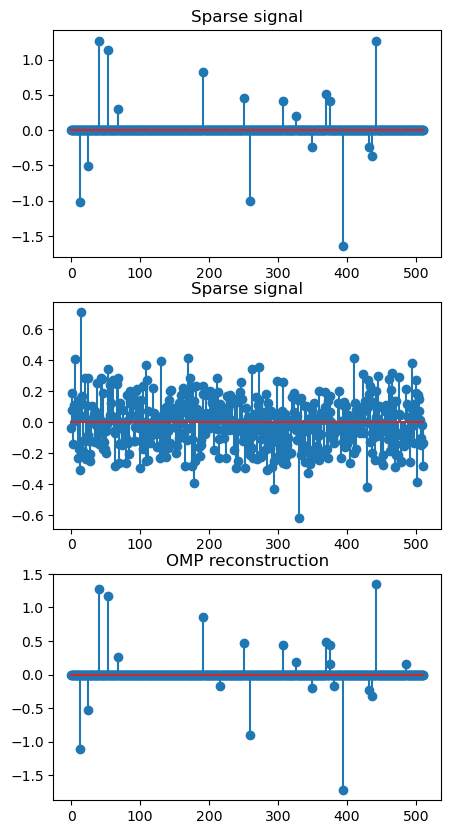

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_sparse_coded_signal
from sklearn.linear_model import OrthogonalMatchingPursuit, OrthogonalMatchingPursuitCV

n_components = n_features = 512
n_nonzero_coefs = 17
n_nonzero_reconstruction_coefs = 21

y, X, w = make_sparse_coded_signal(
    n_samples=1,
    n_components=n_components,
    n_features=n_features,
    n_nonzero_coefs=n_nonzero_coefs,
    random_state=0,
)
X = X.T

x_plot = np.arange(n_features)

# distort the clean signal
y_noisy = y + 0.05 * np.random.randn(len(y))

fig, ax = plt.subplots(3, 1, figsize=(5, 10))

# plot the sparse signal
ax[0].set_title("Sparse signal")
ax[0].stem(x_plot, w)

# plot the noisy signal
ax[1].set_title("Sparse signal")
ax[1].stem(x_plot, y_noisy)

# plot the noisy reconstruction
omp = OrthogonalMatchingPursuit(n_nonzero_coefs=n_nonzero_reconstruction_coefs)
omp.fit(X, y_noisy)
ax[2].set_title("OMP reconstruction")
ax[2].stem(x_plot, omp.coef_)

# My own implementation for circulant matrices

In [2]:
class DictSparseVec:
    def __init__(self, data_dict, length=None, dtype=None):
        if dtype is None:
            self.dtype = type(list(data_dict.values())[0])
        else:
            self.dtype = dtype
        try:
            self.data_dict = {k:self.dtype(v) for k, v in data_dict.items()}
        except ValueError:
            raise ValueError(f"The dictionary values must be convertible to a single dtype ({str(dtype) if dtype is not None else "Unspecified"}).")
        if length is None:
            self.length = max(data_dict.keys()) + 1
        else:
            self.length = length

    @classmethod
    def zeros(cls, length, dtype=float):
        return cls({}, length=length, dtype=dtype)
    
    @classmethod
    def from_vec(cls, vec):
        if isinstance(vec, DictSparseVec):
            return vec
        elif not isinstance(vec, (list, tuple, np.ndarray)):
            raise ValueError("Input must be a list, tuple, or numpy array.")
        vec = np.array(vec)
        non_zero_mask = ~np.isclose(vec, 0)
        non_zero_inds = np.where(non_zero_mask)[0]
        non_zero_vals = vec[non_zero_mask]
        data_dict = {i: val for i, val in zip(non_zero_inds, non_zero_vals)}
        return cls(data_dict, length=len(vec), dtype=vec.dtype.type)
    
    def __len__(self):
        return self.length
    
    def __repr__(self):
        return f"<DictSparseVec: len={self.length}, non_zero={len(self.data_dict.keys())}, dtype={self.dtype}>"
    
    def __add__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot add a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot add vectors of different lengths.")
        all_keys = set(self.data_dict.keys()) | set(other.data_dict.keys())
        try:
            new_data_dict = {k:(self.data_dict.get(k, 0) + other.data_dict.get(k, 0)) for k in all_keys}
        except TypeError:
            raise TypeError("Cannot add vectors with incompatible dtypes.")
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __radd__(self, other):
        return self + other
    
    def __sub__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot subtract a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot subtract vectors of different lengths.")
        all_keys = set(self.data_dict.keys()) | set(other.data_dict.keys())
        try:
            new_data_dict = {k:(self.data_dict.get(k, 0) - other.data_dict.get(k, 0)) for k in all_keys}
        except TypeError:
            raise TypeError("Cannot subtract vectors with incompatible dtypes.")
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __rsub__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot subtract a DictSparseVec from a non-vector object.")
        return other - self
    
    def __mul__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot multiply a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot multiply vectors of different lengths.")
        common_keys = set(self.data_dict.keys()) & set(other.data_dict.keys())
        try:
            new_data_dict = {k:(self.data_dict[k] * other.data_dict[k]) for k in common_keys}
        except TypeError:
            raise TypeError("Cannot multiply vectors with incompatible dtypes.")
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __rmul__(self, other):
        return self * other
    
    def __matmul__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot dot product a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot dot product vectors of different lengths.")
        common_keys = set(self.data_dict.keys()) & set(other.data_dict.keys())
        try:
            result = sum(self.data_dict[k] * other.data_dict[k] for k in common_keys)
        except TypeError:
            raise TypeError("Cannot dot product vectors with incompatible dtypes.")
        return result
    
    def __rmatmul__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot dot product a non-vector object to a DictSparseVec.")
        return other @ self
    
    def convolve(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot convolve a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot convolve vectors of different lengths.")
        new_data_dict = {}
        for kself in self.data_dict.keys():
            for kother in other.data_dict.keys():
                new_key = (kself + kother) % self.length
                if new_key not in new_data_dict:
                    new_data_dict[new_key] = 0
                new_data_dict[new_key] += self.data_dict[kself] * other.data_dict[kother]
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __getitem__(self, key):
        if isinstance(key, int):
            if 0 <= key < self.length:
                return self.data_dict.get(key, 0)
            else:
                raise IndexError("Index out of bounds.")
        elif isinstance(key, slice):
            start, stop, step = key.indices(self.length)
            slice_keys = set(range(start, stop, step))
            present_keys = set(self.data_dict.keys()) & slice_keys
            return DictSparseVec({k: self.data_dict[k] for k in present_keys}, length=len(slice_keys), dtype=self.dtype)
        elif isinstance(key, (list, tuple, np.ndarray)):
            keys = np.array(key)
            if keys.ndim != 1:
                raise ValueError("Index array must be one-dimensional.")
            if not np.issubdtype(keys.dtype, np.integer):
                raise ValueError("Index array must be of integer type.")
            return DictSparseVec({np.argwhere(keys == k)[0][0]: self.data_dict[int(k)] for k in keys if self.data_dict.get(k, 0) != 0}, length=len(keys), dtype=self.dtype)

    def clean_zeros(self):
        """Remove zero entries from the dictionary."""
        self.data_dict = {k: v for k, v in self.data_dict.items() if not np.isclose(v, 0)}
    
    def to_dense(self):
        return np.array([self.data_dict.get(i, 0) for i in range(self.length)], dtype=self.dtype)


In [3]:
from scipy.signal import fftconvolve

n = 5

# a = np.random.randn(n)
# b = np.random.randn(n)

a = np.array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0])
b = np.array([1, 0, 0, 0, 1, 0, 0, 1, 0, 0])

a_s = DictSparseVec.from_vec(a)
b_s = DictSparseVec.from_vec(b)

In [4]:
a

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0])

In [5]:
b

array([1, 0, 0, 0, 1, 0, 0, 1, 0, 0])

In [6]:
a_s.convolve(b_s).to_dense()

array([1, 1, 0, 0, 2, 0, 0, 2, 0, 0])